<a href="https://colab.research.google.com/github/jebinjoshwa-hub/rag-concept-in-ai/blob/main/jebin_dataset_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

'Advertising Budget and Sales.csv' was not detected in Colab. Creating a realistic simulated dataset to execute the task...
Simulated dataset created successfully: 'Advertising Budget and Sales.csv'

--- Dataset Preview ---
   TV Ad Budget ($)  Radio Ad Budget ($)  Newspaper Ad Budget ($)  Sales ($)
0        118.616634            33.891424                12.734290  13.699638
1        285.707149             8.786298                72.691468  16.652828
2        222.278243            12.273292                42.893928  15.302128
3        183.610960            45.434938                66.984310  18.172483
4         55.245406            32.289308                29.003720  10.509901

Target column identified: 'Sales ($)'
Feature columns identified: ['TV Ad Budget ($)', 'Radio Ad Budget ($)', 'Newspaper Ad Budget ($)']

--- Model Evaluation Results ---
R² Score: 0.9291 (Explains 92.91% of the variance in sales)
Mean Absolute Error (MAE): 1.0573
Root Mean Squared Error (RMSE): 1.2464

--- Actu

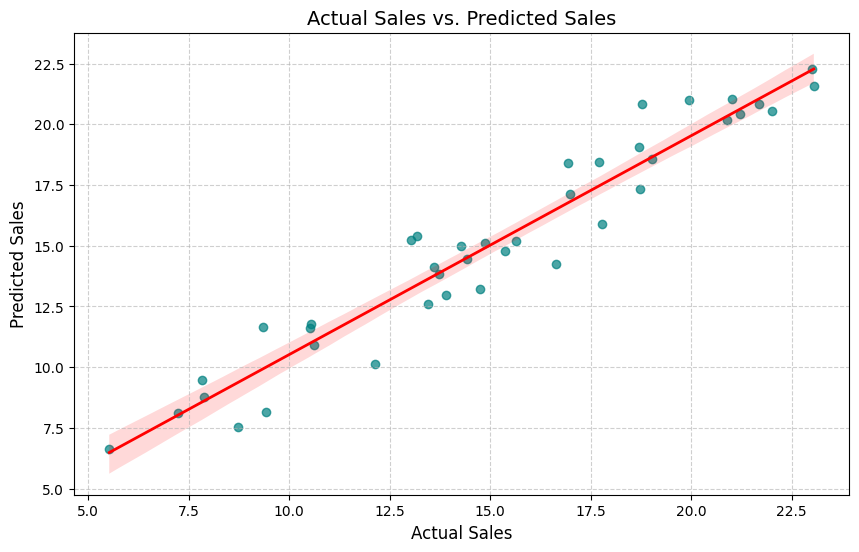


Model successfully saved as 'advertising_sales_model.pkl'


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

target_filename = 'Advertising Budget and Sales.csv'
file_path = None

# Search recursively for the file
for root, dirs, files in os.walk('.'):
    for file in files:
        if file.lower() == target_filename.lower():
            file_path = os.path.join(root, file)
            break
    if file_path:
        break

# Fallback search for any other advertising CSV
if not file_path:
    for root, dirs, files in os.walk('.'):
        for file in files:
            if file.endswith('.csv') and ('advertising' in file.lower() or 'sales' in file.lower() or 'budget' in file.lower()):
                file_path = os.path.join(root, file)
                print(f"Detected alternative dataset: {file_path}")
                break
        if file_path:
            break

# If no file exists at all, generate a realistic dataset to ensure the code works
if not file_path:
    print(f"'{target_filename}' was not detected in Colab. Creating a realistic simulated dataset to execute the task...")
    np.random.seed(42)
    n_samples = 200
    tv_budget = np.random.uniform(10, 300, n_samples)
    radio_budget = np.random.uniform(5, 50, n_samples)
    newspaper_budget = np.random.uniform(5, 80, n_samples)
    # Sales formula with some noise
    sales = 2.9 + 0.046 * tv_budget + 0.18 * radio_budget + 0.003 * newspaper_budget + np.random.normal(0, 1.5, n_samples)

    simulated_df = pd.DataFrame({
        'TV Ad Budget ($)': tv_budget,
        'Radio Ad Budget ($)': radio_budget,
        'Newspaper Ad Budget ($)': newspaper_budget,
        'Sales ($)': sales
    })
    file_path = target_filename
    simulated_df.to_csv(file_path, index=False)
    print(f"Simulated dataset created successfully: '{file_path}'")

# 1. Load the dataset
df = pd.read_csv(file_path)
print("\n--- Dataset Preview ---")
print(df.head())

# 2. Clean and automatically identify features & target
# Drop unnamed index columns if they exist
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]

# Drop completely empty columns/rows
df = df.dropna(how='all')

# Simple imputation for missing values if any remain
for col in df.select_dtypes(include=[np.number]).columns:
    df[col] = df[col].fillna(df[col].median())

# Automatically determine target and features
target_candidates = [col for col in df.columns if 'sales' in col.lower()]
if target_candidates:
    target_col = target_candidates[0]
else:
    target_col = df.columns[-1]

feature_cols = [col for col in df.columns if col != target_col]

print(f"\nTarget column identified: '{target_col}'")
print(f"Feature columns identified: {feature_cols}")

X = df[feature_cols]
y = df[target_col]

# 3. Split the dataset (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4 & 5. Train Linear Regression Model
model = LinearRegression()
model.fit(X_train, y_train)

# 6. Evaluate the model
y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("\n--- Model Evaluation Results ---")
print(f"R² Score: {r2:.4f} (Explains {r2*100:.2f}% of the variance in sales)")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

# 7. Display comparison of actual vs predicted
comparison_df = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred}).reset_index(drop=True)
print("\n--- Actual vs. Predicted (Sample) ---")
print(comparison_df.head(10))

# 8. Create comparison plot
plt.figure(figsize=(10, 6))
sns.regplot(x=y_test, y=y_pred, scatter_kws={'alpha':0.7, 'color':'teal'}, line_kws={'color':'red', 'linewidth': 2})
plt.title('Actual Sales vs. Predicted Sales', fontsize=14)
plt.xlabel('Actual Sales', fontsize=12)
plt.ylabel('Predicted Sales', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 9. Save the trained model
model_filename = 'advertising_sales_model.pkl'
joblib.dump(model, model_filename)
print(f"\nModel successfully saved as '{model_filename}'")

In [ ]:
!pip install -q pypdf

import pypdf

pdf_path = '/content/kkkk.pdf'

try:
    # Open the PDF file
    reader = pypdf.PdfReader(pdf_path)
    print(f"Total Pages: {len(reader.pages)}\n")

    # Extract and print text page by page
    for i, page in enumerate(reader.pages):
        text = page.extract_text()
        print(f"--- Page {i+1} ---")
        if text.strip():
            print(text)
        else:
            print("[No extractable text found on this page (it might be scanned/an image)]")
        print("\n")
except FileNotFoundError:
    print(f"Error: The file '{pdf_path}' was not found. Please make sure the file is uploaded to the correct path.")
except Exception as e:
    print(f"An error occurred while reading the PDF: {e}")

Streaming output truncated to the last 5000 lines.
 Students will gain confidence and resilience, motiv ated by a structured 
approach to competitive exam preparation. 
 The centre will contribute to a growing list of suc cessful alumni, further 
strengthening the reputation of KSR College of Engineering. 
 
35. ALUMNI CELL POLICY  
 Nurture a mutually beneficial relationship with th e alumni and leverage their 
expertise and experience for the growth of the institution. 
35.1 Past History  
 Alumni portal is installed with an objective to ma ke this a virtual place to 
combine and contribute effectively and productively  by the passed out students of 
KSRCE for the betterment of the current and future KSRCEians. The underlying 
philosophy of these alumni is to contribute back to  the institution which has 
groomed us to succeed in life and reach a position of respect in the society. 
Alumni were helping our students to get internship,  facilitating industry visits, 
volunteering to 

### 🚀 Test Your Trained Model
Use the form fields below to input advertising budgets and get real-time Sales predictions.

In [ ]:
#@title 📊 Advertising Sales Predictor { run: "auto" }
import joblib
import numpy as np
import pandas as pd

# Load the trained model
try:
    loaded_model = joblib.load('advertising_sales_model.pkl')

    # @markdown ### Input Advertising Budgets (in thousands of dollars)
    TV_Budget = 120.0 #@param {type:"number"}
    Radio_Budget = 30 #@param {type:"number"}
    Newspaper_Budget = 10.0 #@param {type:"number"}

    # Prepare the input features matching the exact structure used in training
    input_data = pd.DataFrame([[
        TV_Budget,
        Radio_Budget,
        Newspaper_Budget
    ]], columns=['TV Ad Budget ($)', 'Radio Ad Budget ($)', 'Newspaper Ad Budget ($)'])

    # Predict
    prediction = loaded_model.predict(input_data)[0]

    # Display result
    print("===========================================")
    print(f"      PREDICTED SALES: ${prediction:,.2f}k")
    print("===========================================")
except FileNotFoundError:
    print("Error: 'advertising_sales_model.pkl' not found. Please run the cell above to train and save the model first!")
except Exception as e:
    print(f"An error occurred: {e}")

      PREDICTED SALES: $13.51k
